In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

raw = pd.read_csv('../data/raw/elliptic_txs_features.csv', header=None)
num_features = raw.shape[1] - 2  # total features - remove txId and time_step
feature_cols = ['txId', 'time_step'] + [f'feature_{i}' for i in range(1, num_features + 1)]

features = pd.read_csv('../data/raw/elliptic_txs_features.csv', header=None, names=feature_cols)

# Load classes
classes = pd.read_csv('../data/raw/elliptic_txs_classes.csv')

print(features.shape)
print(classes.shape)

(203769, 167)
(203769, 2)


In [4]:
# Merge and clean labels
df = features.merge(classes, on='txId', how='left')
df_labeled = df[df['class'] != 'unknown'].copy()
df_labeled['label'] = df_labeled['class'].apply(lambda x: 1 if x == '1' else 0)

print(df_labeled.shape)
print(df_labeled['label'].value_counts())
print(df_labeled['label'].value_counts(normalize=True) * 100)

(46564, 169)
label
0    42019
1     4545
Name: count, dtype: int64
label
0    90.239241
1     9.760759
Name: proportion, dtype: float64


In [5]:
# Missing values
print("Total nulls:", df_labeled.isnull().sum().sum())
print(df_labeled.isnull().sum()[df_labeled.isnull().sum() > 0])

Total nulls: 0
Series([], dtype: int64)


In [6]:
# Duplicates
print("Duplicate rows:", df_labeled.duplicated().sum())
print("Duplicate txIds:", df_labeled.duplicated(subset='txId').sum())

Duplicate rows: 0
Duplicate txIds: 0


In [9]:
# Data types
feature_columns = [col for col in df_labeled.columns if col.startswith('feature_')]
print(df_labeled[feature_columns].dtypes.value_counts())

float64    165
Name: count, dtype: int64


In [10]:
# Summary statistics
print(df_labeled[feature_columns].describe().T)

               count      mean       std       min       25%       50%  \
feature_1    46564.0 -0.052645  0.702554 -0.172982 -0.172683 -0.170652   
feature_2    46564.0  0.159103  1.544040 -0.210553 -0.162140 -0.113851   
feature_3    46564.0  0.148974  1.063158 -1.756361 -1.201369  0.463609   
feature_4    46564.0  0.172216  1.600931 -0.121970 -0.121970 -0.121970   
feature_5    46564.0  0.028651  1.729706 -0.063725 -0.043875 -0.043875   
...              ...       ...       ...       ...       ...       ...   
feature_161  46564.0  0.057301  1.729502 -0.125939 -0.087490 -0.087490   
feature_162  46564.0  0.076348  1.764513 -0.131155 -0.131155 -0.131155   
feature_163  46564.0  0.045520  1.065455 -0.269818 -0.140597 -0.097524   
feature_164  46564.0 -0.037397  0.998764 -1.760926 -0.120613 -0.120613   
feature_165  46564.0 -0.037899  0.998087 -1.760984 -0.119792 -0.119792   

                  75%         max  
feature_1   -0.141446   39.786756  
feature_2    0.016948   73.595052  
fea

In [11]:
# Feature scale/range
print("Min value across all features:", df_labeled[feature_columns].min().min())
print("Max value across all features:", df_labeled[feature_columns].max().max())

Min value across all features: -13.09335839600819
Max value across all features: 287.8915151668281


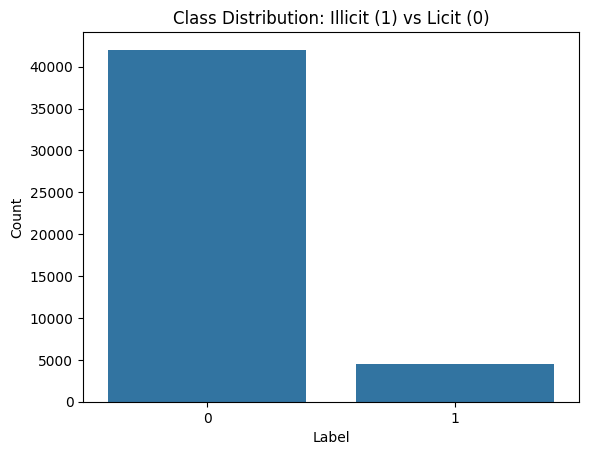

In [12]:
# Visualize the class imbalance
sns.countplot(x='label', data=df_labeled)
plt.title('Class Distribution: Illicit (1) vs Licit (0)')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()

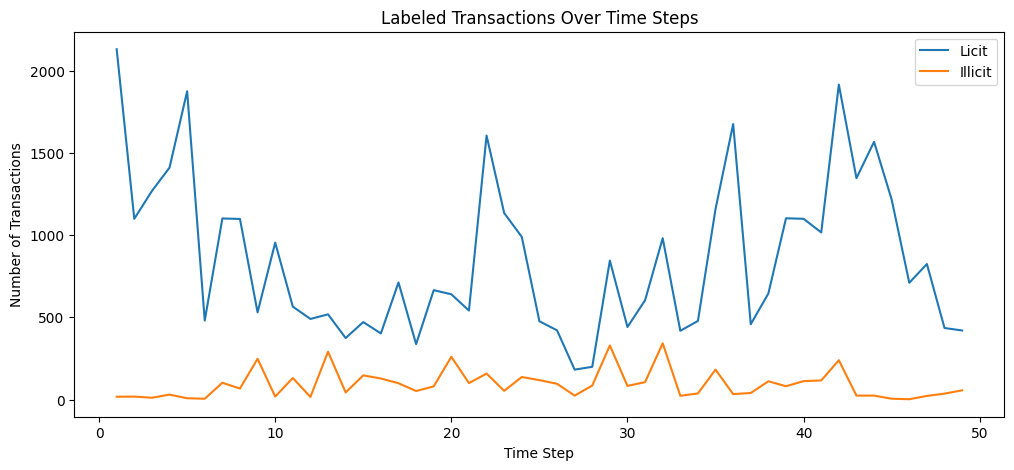

In [13]:
# Transactions over time
time_counts = df_labeled.groupby(['time_step', 'label']).size().unstack(fill_value=0)
time_counts.plot(kind='line', figsize=(12, 5))
plt.title('Labeled Transactions Over Time Steps')
plt.xlabel('Time Step')
plt.ylabel('Number of Transactions')
plt.legend(['Licit', 'Illicit'])
plt.show()

In [8]:
# Save clean data
df_labeled.to_csv('../data/processed/df_labeled.csv', index=False)
print("Saved cleaned dataset to data/processed/")

Saved cleaned dataset to data/processed/
